<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Simulacion_MBG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:magenta;">**Simulación de movimiento browniano geométrico** (MBG)</span>

<span style="color:teal;">**Nombre:** </span> Jerónimo López Annette Michelle

<span style="color:teal;">**Objetivo:** simular un MBG, calcular rendimientos logarítmicos, **estimar $\mu$ y $\sigma$ a partir de los datos** y verificar la normalidad de los rendimientos con gráficas y pruebas estadísticas.</span>

**Importamos las librerias**

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

Definimos una función de autocorrelación de una serie de tiempo unidimensional $x$ hasta un número determinado de rezagos

In [61]:
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x) #se resta la media
    d = np.sum(x**2)
    return np.array([np.sum(x[k:] * x[:len(x)-k]) / d for k in range(nlags + 1)])

<span style="color:red;">**Definimos una funcion: Para realizar la prueba de Ljung-Box:** </span>un test estadístico que sirve para evaluar si los elementos de una serie de tiempo están globalmente autocorrelacionados (es decir, si la serie muestra "memoria" o si sus valores son independientes a lo largo del tiempo).

In [62]:
def ljung_box(x, lags):
    n = len(x); r = acf(x, max(lags)); filas = []
    for h in lags:
        q = n * (n + 2) * np.sum(r[1:h+1]**2 / (n - np.arange(1, h+1)))
        filas.append((h, q, stats.chi2.sf(q, h)))
    return pd.DataFrame(filas, columns=["Rezago", "Estadístico Q", "Valor p"])

Aplicamos la prueba de Lilliefors (una variante de la prueba de Kolmogorov-Smirnov) para verificar si un conjunto de datos sigue una distribución normal, ajustando los parámetros (media y desviación estándar) directamente a partir de la misma muestra.

In [63]:
def lilliefors_norm(x, n_sim=5000, seed=1):
    # KS con parámetros estimados; valor p por Monte Carlo (no depende de tablas)
    def ks(v):
        z = np.sort((v - v.mean()) / v.std(ddof=1)); n = len(z)
        F = stats.norm.cdf(z); i = np.arange(1, n + 1)
        return max(np.max(i / n - F), np.max(F - (i - 1) / n))
    obs = ks(np.asarray(x)); g = np.random.default_rng(seed)
    sim = np.array([ks(g.standard_normal(len(x))) for _ in range(n_sim)])
    return obs, (np.sum(sim >= obs) + 1) / (n_sim + 1)

## <span style="color:teal;">**Parámetros de la simulación**</span>

`mu_real` y `sigma_real` solo se usan para **generar** la serie; los parámetros se estiman desde los rendimientos observados.

In [64]:
P0 = 100.0 #Precio inicial
mu_real = 0.08 # Tasa de rendimiento esperado o drift
sigma_real = 0.20 # volatilidad anual
n = 2520 #Número total de pasos
dt = 1 / 252 #Tamaño del paso de tiempo
rng = np.random.default_rng(42) #semilla

## <span style="color:teal;">**Simulación del MBG**</span>

$P_t=P_0\exp\left[(\mu-\tfrac12\sigma^2)t+\sigma W_t\right]$

In [65]:
Z = rng.standard_normal(n) #arreglo de números aleatorios independientes e idénticamente distribuidos
W = np.concatenate(([0.0], np.cumsum(np.sqrt(dt) * Z))) #Movimiento Browniano Estándar
t = np.arange(n + 1) * dt # vector de tiempo
P = P0 * np.exp((mu_real - 0.5 * sigma_real**2) * t + sigma_real * W)

## <span style="color:teal;">**Rendimientos logarítmicos**</span>

$R_i=\ln(P_i/P_{i-1})$

In [66]:
R = np.log(P[1:] / P[:-1]) #rendimiento

## <span style="color:teal;">**Estimación de parámetros**</span>

Si $R_i\sim N\big((\mu-\tfrac12\sigma^2)\Delta t,\ \sigma^2\Delta t\big)$, entonces:

$$\hat\sigma=\frac{s_R}{\sqrt{\Delta t}},\qquad \hat\mu=\frac{\bar R}{\Delta t}+\tfrac12\hat\sigma^2$$

donde $\bar R$ y $s_R$ son la media y desviación estándar muestrales (con $n-1$).

In [67]:
def estimar_parametros(R, dt):
    """Estima (mu, sigma) anuales del MBG a partir de rendimientos logarítmicos."""
    media_R = np.mean(R)
    desv_R = np.std(R, ddof=1)
    sigma_hat = desv_R / np.sqrt(dt)
    mu_hat = media_R / dt + 0.5 * sigma_hat**2
    return mu_hat, sigma_hat, media_R, desv_R

In [68]:
mu_hat, sigma_hat, media_R, desv_R = estimar_parametros(R, dt)

In [69]:
#creamos una tabla
tabla = pd.DataFrame({
    "Parámetro": ["mu (deriva anual)", "sigma (volatilidad anual)"],
    "Real": [mu_real, sigma_real],
    "Estimado": [mu_hat, sigma_hat],
})
print(tabla.to_string(index=False))
print(f"\nMedia diaria de R: {media_R:.6f} | Desv. estándar diaria de R: {desv_R:.6f}")

# Error estándar aproximado de mu_hat: sigma/sqrt(T), T = n*dt años
T = n * dt
print(f"Error estándar aprox. de mu_hat: {sigma_hat/np.sqrt(T):.4f}  (mu es difícil de estimar con pocos años)")

                Parámetro  Real  Estimado
        mu (deriva anual)  0.08 -0.048243
sigma (volatilidad anual)  0.20  0.201042

Media diaria de R: -0.000272 | Desv. estándar diaria de R: 0.012664
Error estándar aprox. de mu_hat: 0.0636  (mu es difícil de estimar con pocos años)


## <span style="color:teal;">**Gráficas de la serie**</span>

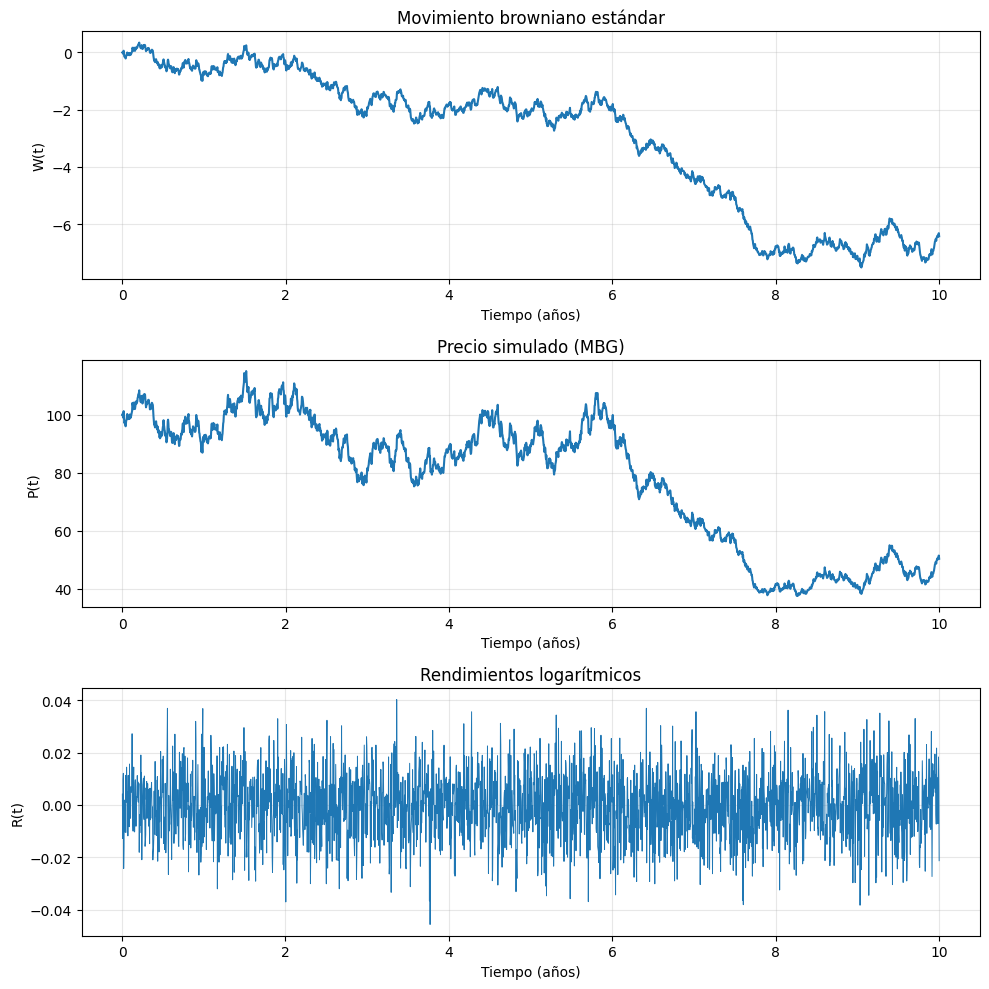

In [70]:
fig, ax = plt.subplots(3, 1, figsize=(10, 10))
ax[0].plot(t, W); ax[0].set_title("Movimiento browniano estándar"); ax[0].set_ylabel("W(t)")
ax[1].plot(t, P); ax[1].set_title("Precio simulado (MBG)"); ax[1].set_ylabel("P(t)")
ax[2].plot(t[1:], R, lw=0.7); ax[2].set_title("Rendimientos logarítmicos"); ax[2].set_ylabel("R(t)")
for a in ax:
    a.set_xlabel("Tiempo (años)"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## <span style="color:teal;">**Histograma con la normal **ajustada** (muestra $\hat\mu$ y $\hat\sigma$)**</span>

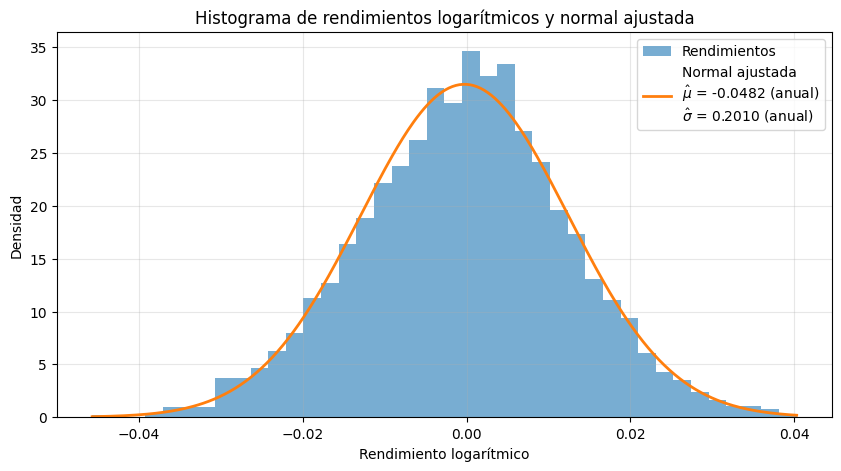

mu estimado = -0.048243
sigma estimado = 0.201042


In [71]:
def histograma_normalidad(R, dt, bins=40):
    """Grafica el histograma de R con la normal ajustada y devuelve (mu_hat, sigma_hat)."""
    mu_h, sig_h, m, s = estimar_parametros(R, dt)
    x = np.linspace(R.min(), R.max(), 400)
    plt.figure(figsize=(10, 5))
    plt.hist(R, bins=bins, density=True, alpha=0.6, label="Rendimientos")
    plt.plot(x, stats.norm.pdf(x, m, s), lw=2,
             label=f"Normal ajustada\n$\\hat\\mu$ = {mu_h:.4f} (anual)\n$\\hat\\sigma$ = {sig_h:.4f} (anual)")
    plt.title("Histograma de rendimientos logarítmicos y normal ajustada")
    plt.xlabel("Rendimiento logarítmico"); plt.ylabel("Densidad")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
    return mu_h, sig_h

mu_est, sigma_est = histograma_normalidad(R, dt)
print(f"mu estimado = {mu_est:.6f}")
print(f"sigma estimado = {sigma_est:.6f}")

## <span style="color:teal;">**Gráfico Q-Q**</span>

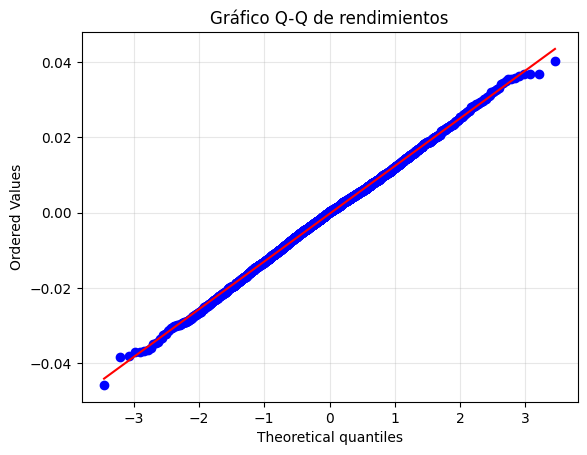

In [72]:
stats.probplot(R, dist="norm", plot=plt)
plt.title("Gráfico Q-Q de rendimientos"); plt.grid(alpha=0.3); plt.show()

<span style="color:blue:;">**Interpretación**</span>

> * La línea recta diagonal:
Representa el comportamiento ideal si los datos fueran perfectamente normales.

> * Puntos sobre la línea: En las zonas donde los puntos caen exactamente sobre la recta, los rendimientos se comportan como una distribución normal.

> * Puntos alejados de la línea (en los extremos): Indican desviaciones respecto a la normalidad.

En series financieras es muy común observar desviaciones en los extremos ("colas"):


* Cola izquierda por debajo de la línea: Hay pérdidas extremas más frecuentes o más severas de lo que predice la curva normal.

* Cola derecha por encima de la línea: Hay ganancias extremas mayores a las esperadas por una normal.

Conclusión: Es el patrón típico del riesgo financiero real.

## <span style="color:teal;">**Autocorrelación (independencia de los rendimientos)**</span>

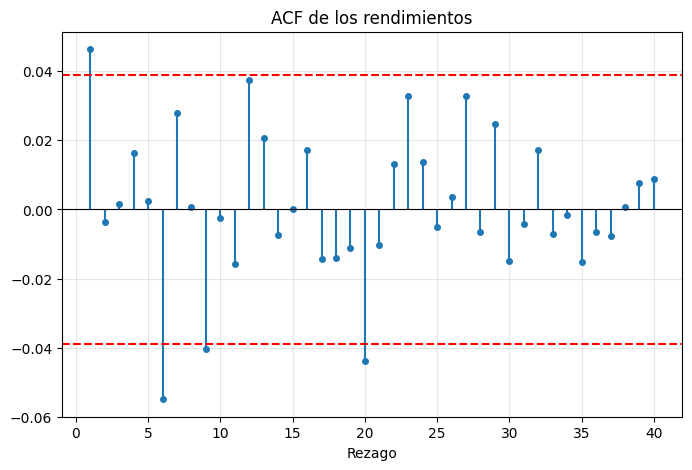

 Rezago  Estadístico Q  Valor p
     10      19.923721 0.029982
     20      32.318757 0.040018
Rezagos fuera de la banda: 4 de 40


In [73]:
fig, ax = plt.subplots(figsize=(8, 5))
r = acf(R, 40); banda = 1.96 / np.sqrt(len(R))
ax.vlines(np.arange(1, 41), 0, r[1:], color="C0"); ax.plot(np.arange(1, 41), r[1:], "o", color="C0", ms=4)
ax.axhline(0, color="k", lw=0.8); ax.axhline(banda, color="r", ls="--"); ax.axhline(-banda, color="r", ls="--")
ax.set_title("ACF de los rendimientos"); ax.set_xlabel("Rezago"); ax.grid(alpha=0.3)
plt.show()

lb = ljung_box(R, [10, 20])
print(lb.to_string(index=False))
print("Rezagos fuera de la banda:", int(np.sum(np.abs(r[1:]) > banda)), "de 40")

<span style="color:blue;">**Interpretación:**</span>

Ausencia de memoria general:

* La inmensa mayoría de las barras se mantienen holgadamente dentro de los límites de las líneas rojas. Esto significa que, en términos generales, los rendimientos pasados no ayudan a predecir los rendimientos futuros.   

* Hay Puntos fuera de los límites (Atípicos o ruido estadístico).   

> Conclusión Financiera y Econométrica
* Hipótesis del Mercado Eficiente (Forma Débil):
El gráfico es consistente con la idea de que los rendimientos se comportan como una caminata aleatoria o ruido blanco, lo cual valida el modelo de Movimiento Browniano Geométrico que simulaste antes.

* No hay patrones estacionales o autorregresivos claros:
No se observa una caída gradual (como en un proceso AR) ni picos periódicos constantes.

## <span style="color:teal;">**Pruebas de normalidad**</span>

Como $\mu$ y $\sigma$ se **estiman** con los mismos datos, la prueba de Kolmogorov-Smirnov clásica (con parámetros fijos) pierde validez: su valor p sale artificialmente alto. Se usa la corrección de **Lilliefors** y se complementa con **Shapiro-Wilk** y **Jarque-Bera**.

$H_0$: los rendimientos siguen una distribución normal.

In [74]:
ks_stat, ks_p = lilliefors_norm(R)
sw_stat, sw_p = stats.shapiro(R)
jb_stat, jb_p = stats.jarque_bera(R)

In [75]:
pruebas = pd.DataFrame({
    "Prueba": ["Lilliefors (KS con parámetros estimados)", "Shapiro-Wilk", "Jarque-Bera"],
    "Estadístico": [ks_stat, sw_stat, jb_stat],
    "Valor p": [ks_p, sw_p, jb_p],
    "Decisión (5%)": ["No se rechaza H0" if p > 0.05 else "Se rechaza H0" for p in (ks_p, sw_p, jb_p)],
})
print(pruebas.to_string(index=False))
print(f"\nAsimetría: {stats.skew(R):.4f} | Curtosis en exceso: {stats.kurtosis(R):.4f}")

                                  Prueba  Estadístico  Valor p    Decisión (5%)
Lilliefors (KS con parámetros estimados)     0.016229 0.114777 No se rechaza H0
                            Shapiro-Wilk     0.999125 0.263468 No se rechaza H0
                             Jarque-Bera     1.043043 0.593617 No se rechaza H0

Asimetría: -0.0472 | Curtosis en exceso: 0.0319


In [76]:
# Creamos una tabla con los datos de tiempo. precio y rendimiento
resultados = pd.DataFrame({"Tiempo (años)": t, "Precio P_t": P, "Rendimiento R_t": np.concatenate(([np.nan], R))})
resultados.to_csv("resultados_mbg.csv", index=False)
resultados.head()

,Tiempo (años),Precio P_t,Rendimiento R_t
0,0.000000,100.000000,NaN
1,0.003968,100.408549,0.004077
2,0.007937,99.125119,-0.012864
3,0.011905,100.090600,0.009693
4,0.015873,101.307847,0.012088


## <span style="color:orange;">**Conclusiones**</span>


- **Parámetros.** $\hat\sigma\approx 0.201$ queda muy cerca de $\sigma=0.20$: la volatilidad se estima con precisión. $\hat\mu\approx -0.048$ se aleja de $\mu=0.08$  porque su error estándar es $\approx\sigma/\sqrt{T}$ y depende de los *años* observados, no del número de datos diarios; es una limitación propia del modelo, no un error del código.
- **Serie.** $W_t$ es una trayectoria aleatoria sin tendencia; $P_t$ siempre es positivo y crece en promedio con $\mu$; los rendimientos oscilan alrededor de cero con amplitud estable (sin agrupamientos de volatilidad).
- **Histograma.** La campana ajustada con $\hat\mu,\hat\sigma$ coincide con el histograma: simetría y colas coherentes con una normal.
- **Q-Q.** Los puntos siguen la recta; solo los extremos pueden separarse un poco, normal en muestras grandes.
- **ACF / Ljung-Box.** 36 de 40 rezagos caen dentro de la banda (con 95 % se esperan ~2 fuera; aquí hay 4). Ljung-Box da p ≈ 0.030 (10 rezagos) y 0.040 (20): evidencia débil, marginal, compatible con azar de la muestra: los incrementos se generaron independientes, así que **no hay dependencia real**.
- **Pruebas de normalidad.** Lilliefors (p ≈ 0.11), Shapiro-Wilk (p ≈ 0.26) y Jarque-Bera (p ≈ 0.59) no rechazan la normalidad; asimetría −0.05 y curtosis en exceso 0.03, casi nulas. Recuerda que no rechazar $H_0$ no prueba normalidad exacta; es consistencia con ella.

**Conclusión:** los rendimientos logarítmicos del MBG simulado son consistentes con $N\big((\mu-\tfrac12\sigma^2)\Delta t,\sigma^2\Delta t\big)$, independientes y de varianza constante; el modelo reproduce lo que establece la teoría y los parámetros se recuperan razonablemente a partir de los datos.